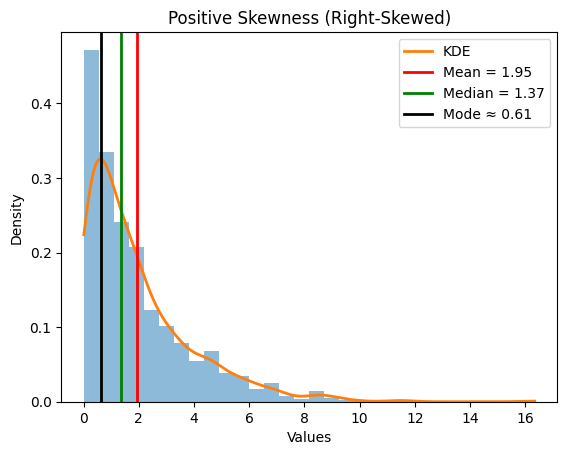

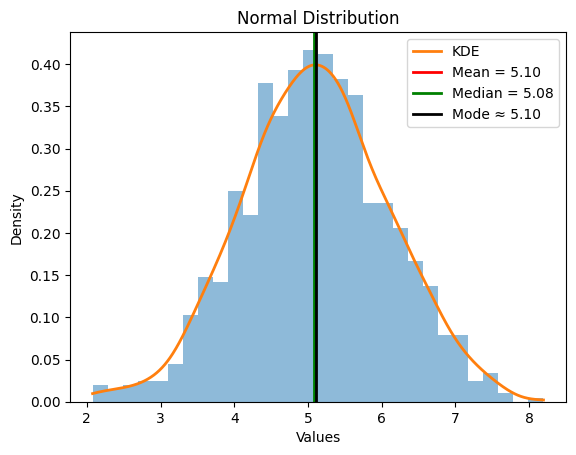

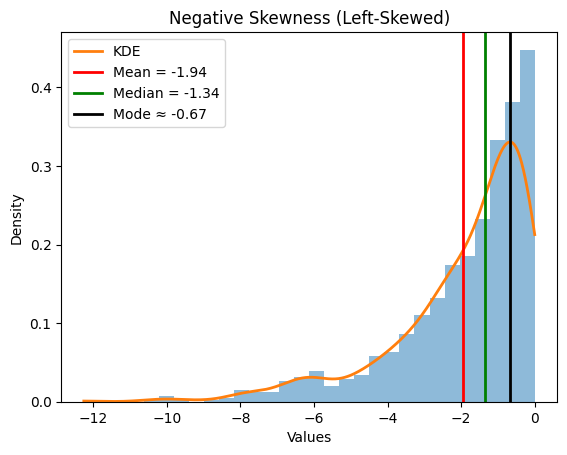

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# Generate data
np.random.seed(42)

# Positive skewness (right-skewed)
positive = np.random.exponential(scale=2, size=1000)

# Normal distribution
normal = np.random.normal(loc=5, scale=1, size=1000)

# Negative skewness (left-skewed)
negative = -np.random.exponential(scale=2, size=1000)


# Function to plot distribution
def plot_distribution(data, title):

    # Mean
    mean = np.mean(data)

    # Median
    median = np.median(data)

    # KDE
    kde = gaussian_kde(data)

    x = np.linspace(min(data), max(data), 1000)
    y = kde(x)

    # Mode = x-value where KDE is maximum
    mode = x[np.argmax(y)]

    # Plot histogram
    plt.hist(
        data,
        bins=30,
        density=True,
        alpha=0.5
    )

    # KDE curve
    plt.plot(
        x,
        y,
        linewidth=2,
        label="KDE"
    )

    # Mean
    plt.axvline(
        mean,
        linewidth=2,
        color = 'red',
        label=f"Mean = {mean:.2f}"
    )

    # Median
    plt.axvline(
        median,
        linewidth=2,
        color = 'green',
        label=f"Median = {median:.2f}"
    )

    # Mode
    plt.axvline(
        mode,
        linewidth=2,
        color = 'black',
        label=f"Mode ≈ {mode:.2f}"
    )

    plt.title(title)
    plt.xlabel("Values")
    plt.ylabel("Density")
    plt.legend()
    plt.show()


# Plot all three
plot_distribution(positive, "Positive Skewness (Right-Skewed)")
plot_distribution(normal, "Normal Distribution")
plot_distribution(negative, "Negative Skewness (Left-Skewed)")

In [9]:
from scipy.stats import skew

def plot_distribution(data, title):

    # Mean
    mean = np.mean(data)

    # Median
    median = np.median(data)

    # KDE
    kde = gaussian_kde(data)

    x = np.linspace(min(data), max(data), 1000)
    y = kde(x)

    # Mode
    mode = x[np.argmax(y)]

    # Skewness
    skewness = skew(data)

    print(f"{title}")
    print(f"Mean = {mean:.2f}")
    print(f"Median = {median:.2f}")
    print(f"Mode ≈ {mode:.2f}")
    print(f"Skewness = {skewness:.2f}")
    print()

    # Plot histogram
    plt.hist(
        data,
        bins=30,
        density=True,
        alpha=0.5
    )

    # KDE curve
    plt.plot(
        x,
        y,
        linewidth=2,
        label="KDE"
    )

    # Mean
    plt.axvline(
        mean,
        linewidth=2,
        color='red',
        label=f"Mean = {mean:.2f}"
    )

    # Median
    plt.axvline(
        median,
        linewidth=2,
        color='green',
        label=f"Median = {median:.2f}"
    )

    # Mode
    plt.axvline(
        mode,
        linewidth=2,
        color='black',
        label=f"Mode ≈ {mode:.2f}"
    )

    plt.title(title)
    plt.xlabel("Values")
    plt.ylabel("Density")
    plt.legend()
    plt.show()

In [11]:
from scipy.stats import skew

print("Positive skewness:", skew(positive))
print("Normal skewness:", skew(normal))
print("Negative skewness:", skew(negative))

Positive skewness: 1.865034222864843
Normal skewness: -0.036662811518565
Negative skewness: -1.6510942321423066


Heavy-tail kurtosis: 20.517095960310094
Normal kurtosis: -0.006749266173800894
Light-tail kurtosis: -1.1833694576178597


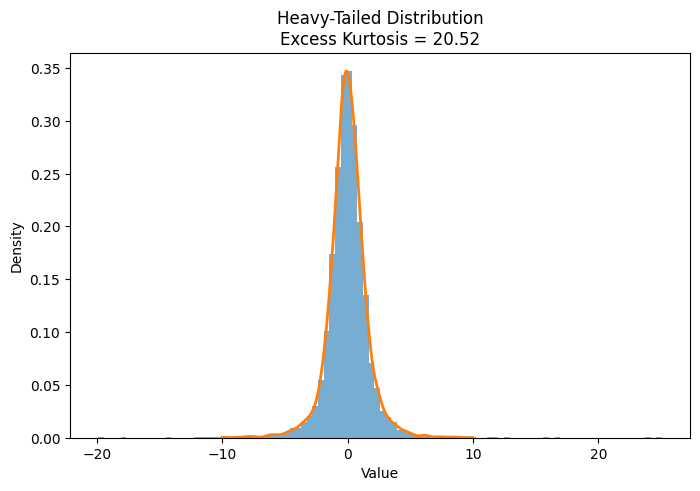

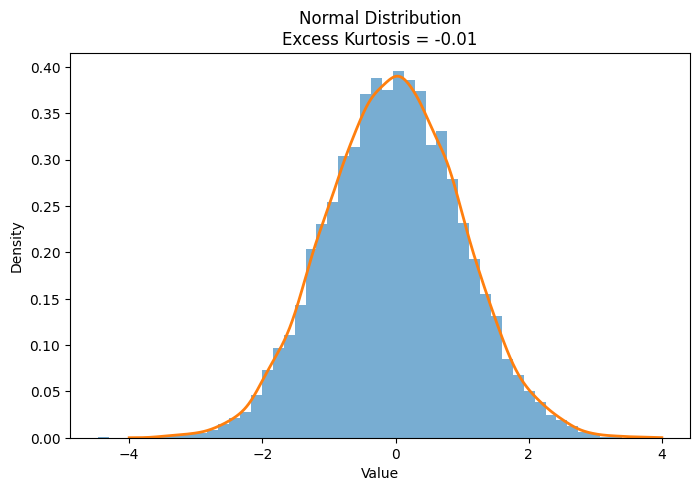

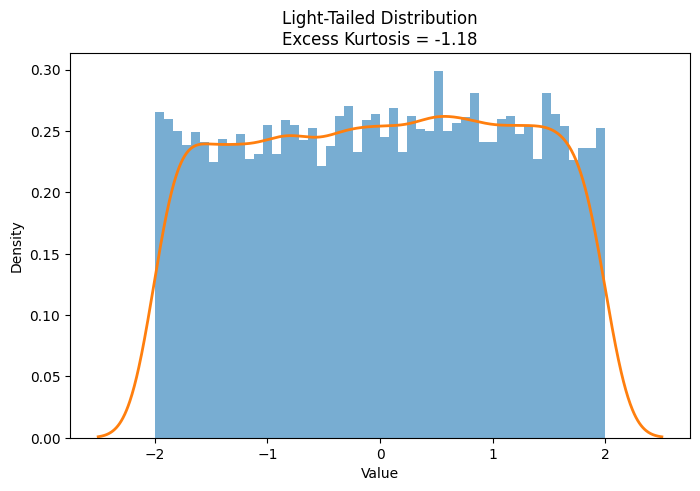

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kurtosis, gaussian_kde

np.random.seed(42)

# 1. Heavy-tailed distribution
heavy = np.random.standard_t(df=3, size=10000)

# 2. Normal distribution
normal = np.random.normal(loc=0, scale=1, size=10000)

# 3. Light-tailed distribution
light = np.random.uniform(-2, 2, size=10000)


# Calculate excess kurtosis
print("Heavy-tail kurtosis:", kurtosis(heavy))
print("Normal kurtosis:", kurtosis(normal))
print("Light-tail kurtosis:", kurtosis(light))


# -------------------------
# Heavy-tailed distribution
# -------------------------
plt.figure(figsize=(8, 5))

plt.hist(heavy, bins=100, density=True, alpha=0.6)

# KDE
x = np.linspace(-10, 10, 1000)
kde = gaussian_kde(heavy)
plt.plot(x, kde(x), linewidth=2)

plt.title(f"Heavy-Tailed Distribution\nExcess Kurtosis = {kurtosis(heavy):.2f}")
plt.xlabel("Value")
plt.ylabel("Density")
plt.show()


# -------------------------
# Normal distribution
# -------------------------
plt.figure(figsize=(8, 5))

plt.hist(normal, bins=50, density=True, alpha=0.6)

# KDE
x = np.linspace(-4, 4, 1000)
kde = gaussian_kde(normal)
plt.plot(x, kde(x), linewidth=2)

plt.title(f"Normal Distribution\nExcess Kurtosis = {kurtosis(normal):.2f}")
plt.xlabel("Value")
plt.ylabel("Density")
plt.show()


# -------------------------
# Light-tailed distribution
# -------------------------
plt.figure(figsize=(8, 5))

plt.hist(light, bins=50, density=True, alpha=0.6)

# KDE
x = np.linspace(-2.5, 2.5, 1000)
kde = gaussian_kde(light)
plt.plot(x, kde(x), linewidth=2)

plt.title(f"Light-Tailed Distribution\nExcess Kurtosis = {kurtosis(light):.2f}")
plt.xlabel("Value")
plt.ylabel("Density")
plt.show()

In [2]:
import numpy as np
from scipy.stats import boxcox

# Positive data
X = np.array([10, 12, 15, 18, 20, 25, 30, 40, 60, 100, 150, 300])

# Apply Box-Cox
X_boxcox, lambda_boxcox = boxcox(X)

print("Original data:")
print(X)

print("\nBox-Cox transformed data:")
print(X_boxcox)

print("\nOptimal lambda:")
print(lambda_boxcox)

Original data:
[ 10  12  15  18  20  25  30  40  60 100 150 300]

Box-Cox transformed data:
[1.50786413 1.57822131 1.65766717 1.71754231 1.75021374 1.81504786
 1.86391073 1.93415141 2.02044477 2.1111032  2.17103369 2.2535439 ]

Optimal lambda:
-0.3978727501273978


Box-Cox lambda: -0.3978727501273978


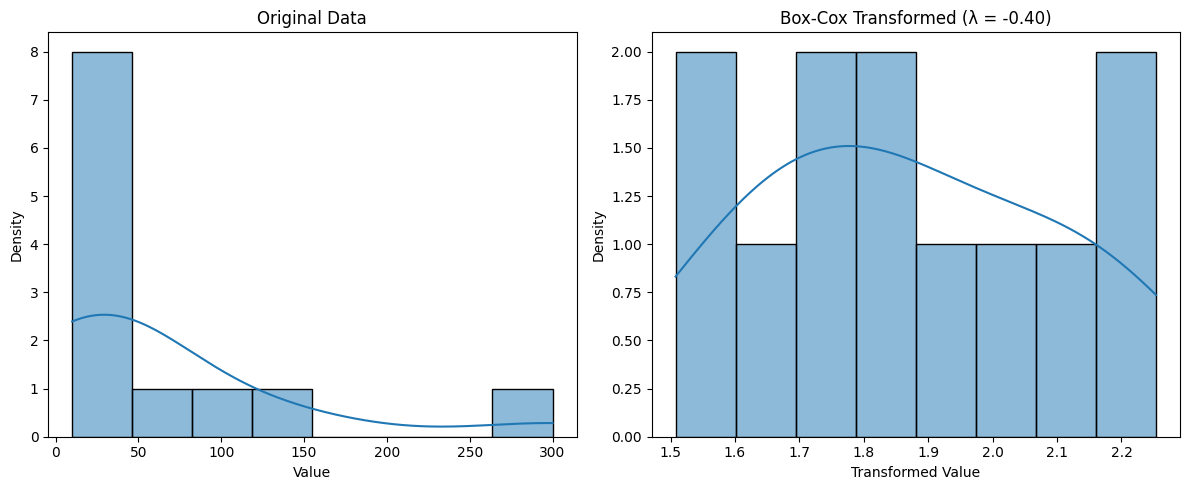

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import boxcox
import seaborn as sns

# Skewed positive data
X = np.array([
    10, 12, 15, 18, 20, 25,
    30, 40, 60, 100, 150, 300
])

# Apply Box-Cox
X_boxcox, lambda_boxcox = boxcox(X)

print("Box-Cox lambda:", lambda_boxcox)

# Create plots
plt.figure(figsize=(12, 5))

# Original data
plt.subplot(1, 2, 1)
sns.histplot(X, kde=True, bins=8)
plt.title("Original Data")
plt.xlabel("Value")
plt.ylabel("Density")

# Box-Cox transformed data
plt.subplot(1, 2, 2)
sns.histplot(X_boxcox, kde=True, bins=8)
plt.title(f"Box-Cox Transformed (λ = {lambda_boxcox:.2f})")
plt.xlabel("Transformed Value")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

Yeo-Johnson lambda: 0.9090980955368206


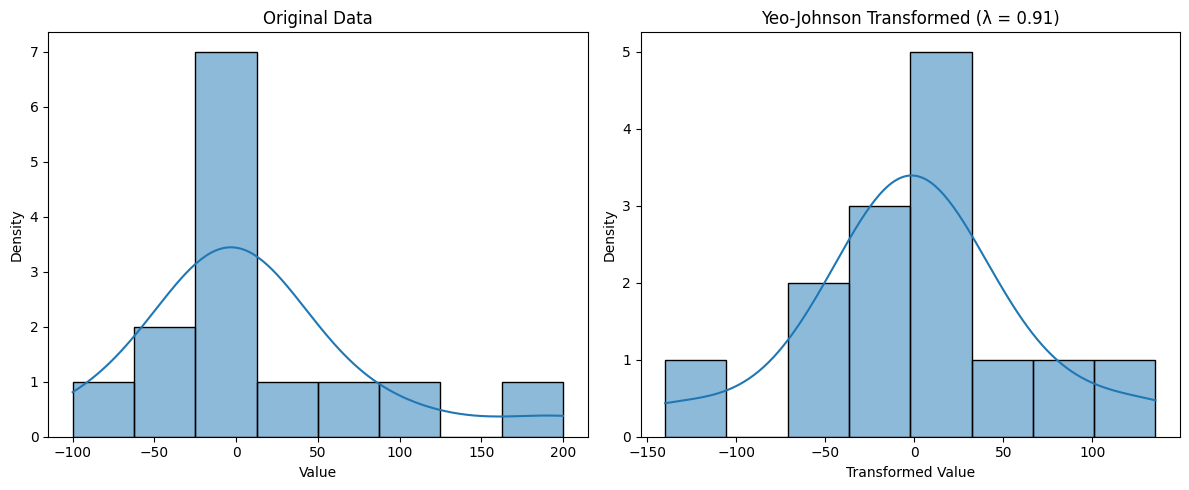

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import yeojohnson
import seaborn as sns

# Data containing negative, zero and positive values
X = np.array([
    -100, -50, -30, -20, -10,
    -5, 0, 2, 5, 10, 20, 50, 100, 200
])

# Apply Yeo-Johnson
X_yeojohnson, lambda_yeojohnson = yeojohnson(X)

print("Yeo-Johnson lambda:", lambda_yeojohnson)

# Create plots
plt.figure(figsize=(12, 5))

# Original data
plt.subplot(1, 2, 1)
sns.histplot(X, kde=True, bins=8)
plt.title("Original Data")
plt.xlabel("Value")
plt.ylabel("Density")

# Yeo-Johnson transformed data
plt.subplot(1, 2, 2)
sns.histplot(X_yeojohnson, kde=True, bins=8)
plt.title(f"Yeo-Johnson Transformed (λ = {lambda_yeojohnson:.2f})")
plt.xlabel("Transformed Value")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

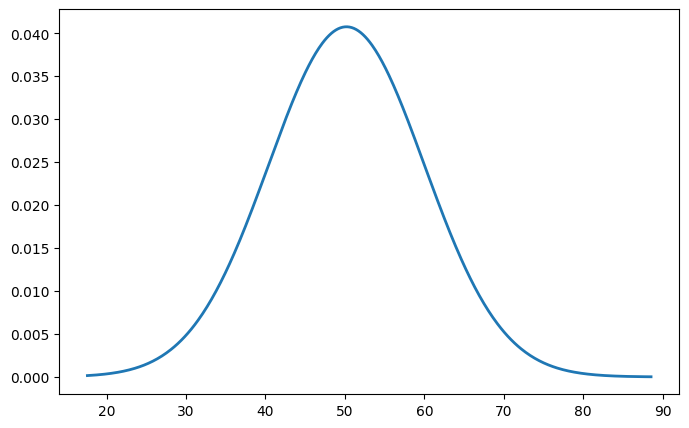

In [6]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

data = np.random.normal(50, 10, 1000)

x = np.linspace(data.min(), data.max(), 500)

mean = np.mean(data)
std = np.std(data)

y = (1 / (std * np.sqrt(2 * np.pi))) * np.exp(
    -0.5 * ((x - mean) / std) ** 2
)

plt.figure(figsize=(8, 5))
plt.plot(x, y, linewidth=2)



plt.show()

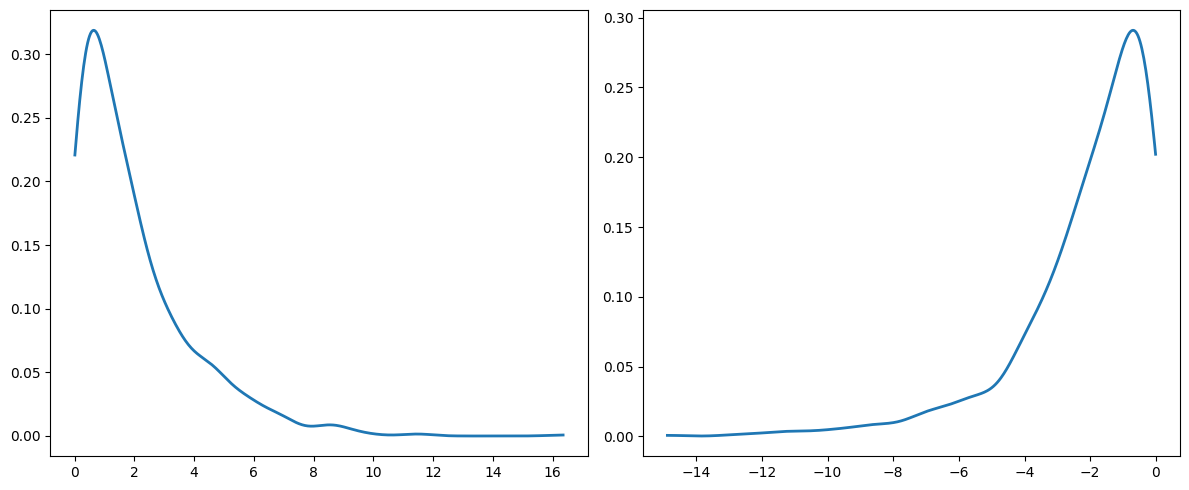

In [5]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Generate data
right_skewed = np.random.exponential(scale=2, size=1000)
left_skewed = -np.random.exponential(scale=2, size=1000)


# Simple KDE function
def kde(data, x):
    n = len(data)
    std = np.std(data)
    h = 1.06 * std * n ** (-1/5)   # Silverman's rule

    kde_values = np.zeros_like(x)

    for value in data:
        kde_values += np.exp(-0.5 * ((x - value) / h) ** 2)

    kde_values /= (n * h * np.sqrt(2 * np.pi))

    return kde_values


# X ranges
x_right = np.linspace(
    right_skewed.min(),
    right_skewed.max(),
    500
)

x_left = np.linspace(
    left_skewed.min(),
    left_skewed.max(),
    500
)


# Calculate KDE
y_right = kde(right_skewed, x_right)
y_left = kde(left_skewed, x_left)


# Plot side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Right skewed
axes[0].plot(x_right, y_right, linewidth=2)


# Left skewed
axes[1].plot(x_left, y_left, linewidth=2)


plt.tight_layout()
plt.show()

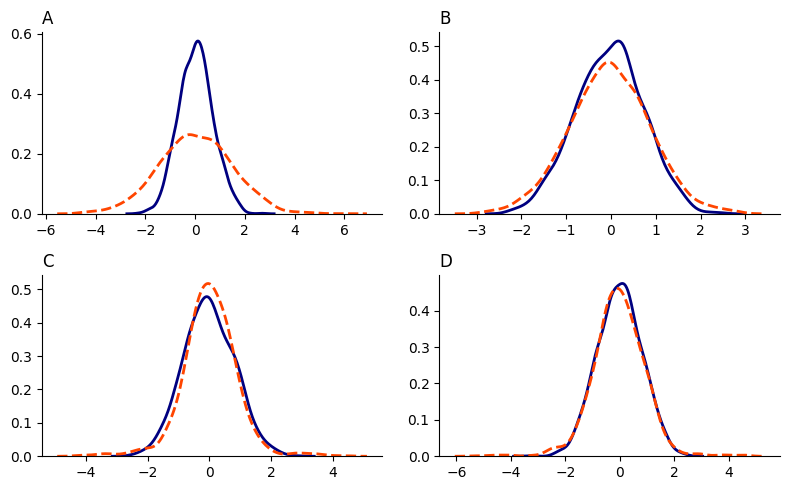

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

fig, axes = plt.subplots(2, 2, figsize=(8, 5))

# ---------------- A: Much heavier tails ----------------
blue_A = np.random.normal(0, 0.7, 1500)
orange_A = np.random.normal(0, 1.5, 1500)

sns.kdeplot(blue_A, ax=axes[0,0],
            color="navy", linewidth=2)
sns.kdeplot(orange_A, ax=axes[0,0],
            color="orangered", linestyle="--", linewidth=2)

axes[0,0].set_title("A", loc="left")


# ---------------- B: Slightly heavier tails ----------------
blue_B = np.random.normal(0, 0.75, 1500)
orange_B = np.random.normal(0, 0.9, 1500)

sns.kdeplot(blue_B, ax=axes[0,1],
            color="navy", linewidth=2)
sns.kdeplot(orange_B, ax=axes[0,1],
            color="orangered", linestyle="--", linewidth=2)

axes[0,1].set_title("B", loc="left")


# ---------------- C: Orange has heavier tails ----------------
blue_C = np.random.normal(0, 0.8, 1500)

# Mostly concentrated around center + a few extreme values
orange_C = np.concatenate([
    np.random.normal(0, 0.65, 1300),
    np.random.normal(0, 2.0, 200)
])

sns.kdeplot(blue_C, ax=axes[1,0],
            color="navy", linewidth=2)
sns.kdeplot(orange_C, ax=axes[1,0],
            color="orangered", linestyle="--", linewidth=2)

axes[1,0].set_title("C", loc="left")


# ---------------- D: Similar center, different tails ----------------
blue_D = np.random.normal(0, 0.85, 1500)

orange_D = np.concatenate([
    np.random.normal(0, 0.8, 1350),
    np.random.normal(0, 1.8, 150)
])

sns.kdeplot(blue_D, ax=axes[1,1],
            color="navy", linewidth=2)
sns.kdeplot(orange_D, ax=axes[1,1],
            color="orangered", linestyle="--", linewidth=2)

axes[1,1].set_title("D", loc="left")


# Clean appearance
for ax in axes.flat:
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()